# Q2 Customer support tool calling
Riya Bhart | 23k0063



In [1]:
import json,random
from pathlib import Path
SEED=230063
TOOLS={
    'check_order_status':('order_id',['What is the status of order {}?','Could you tell me whether order {} has been processed?','I placed order {} last Tuesday. Where is it in the order process?']),
    'initiate_refund':('order_id',['Please start a refund for order {}.','I confirm that I want my money back for order {}.','Go ahead and request a refund for order {}.']),
    'track_shipment':('tracking_id',['Where is parcel {} right now?','Track shipment {} for me.','The carrier gave me tracking number {}. Where is the package?']),
    'escalate_to_human':('case_id',['Connect me with a person about case {}.','I need a human agent for case {}.','Please escalate case {} to a supervisor.'])
}
SYSTEM='Return a single JSON object with keys name and arguments and no commentary. '
SYSTEM+='; '.join(f'{name} requires {arg} (string)' for name,(arg,_) in TOOLS.items())
rng=random.Random(SEED)
pool={}
for k,(name,(arg,templates)) in enumerate(TOOLS.items()):
    records=[]
    for i in range(600):
        ident=f'{100000+k*10000+i}'
        prompt=templates[i%len(templates)].format(ident)
        records.append(dict(id=ident,user=prompt,gold={'name':name,'arguments':{arg:ident}}))
    rng.shuffle(records)
    pool[name]=records
train=[e for rows in pool.values() for e in rows[:450]]
test=[e for rows in pool.values() for e in rows[450:500]]
valid=[e for rows in pool.values() for e in rows[500:550]]
for rows in (train,valid,test): rng.shuffle(rows)
assert (len(train),len(test),len(valid))==(1800,200,200)
assert len({e['id'] for e in train+valid+test})==2200
out=Path('q2_results')
out.mkdir(exist_ok=True)
(out/'split_ids.json').write_text(json.dumps({k:[e['id'] for e in v] for k,v in [('train',train),('validation',valid),('test',test)]},indent=2))
def score(raw,gold):
    def reject(x): raise ValueError(x)
    def unique(pairs):
        obj=dict(pairs)
        if len(obj)!=len(pairs): raise ValueError('duplicate key')
        return obj
    try: obj=json.loads(raw,parse_constant=reject,object_pairs_hook=unique)
    except ValueError: return (False,False,False,'broken JSON')
    tool=isinstance(obj,dict) and obj.get('name')==gold['name']
    exact=tool and obj==gold
    label='correct' if exact else ('argument or schema mismatch' if tool else ('no tool' if not isinstance(obj,dict) or not obj.get('name') else 'wrong tool'))
    return True,tool,exact,label
gold={'name':'track_shipment','arguments':{'tracking_id':'42'}}
assert score(json.dumps(gold),gold)[:3]==(True,True,True)
assert score('Here is '+json.dumps(gold),gold)[:3]==(False,False,False)
assert score('{"name":"track_shipment","arguments":{"tracking_id":42}}',gold)[:3]==(True,True,False)
print('Verified split sizes and scorer on CPU:',len(train),len(valid),len(test))


Verified split sizes and scorer on CPU: 1800 200 200


In [2]:
%pip install -U bitsandbytes

In [3]:
# Single-GPU Linux environment, Python 3.11 recommended.
# Install CUDA PyTorch for your driver, then:
# pip install transformers==4.51.3 peft==0.15.2 accelerate==1.6.0 bitsandbytes==0.45.5 matplotlib
import gc,time,csv
import torch
from transformers import AutoTokenizer,AutoModelForCausalLM,BitsAndBytesConfig,get_linear_schedule_with_warmup,set_seed
from peft import LoraConfig,AdaLoraConfig,get_peft_model,prepare_model_for_kbit_training
from huggingface_hub import model_info
assert torch.cuda.is_available(), 'A CUDA GPU is required for the matched experiment'
BASE='Qwen/Qwen2.5-1.5B-Instruct'
revision_file=out/'base_revision.txt'
if not revision_file.exists():
    revision_file.write_text(model_info(BASE).sha)
revision=revision_file.read_text().strip()
dtype=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
tok=AutoTokenizer.from_pretrained(BASE,revision=revision)
set_seed(SEED)
TARGET=['q_proj','v_proj']
EPOCHS,ACCUM,LR=2,4,2e-4
STEPS=len(train)*EPOCHS//ACCUM
def prompt_tokens(e):
    messages = [
        {"role": "system", "content": SYSTEM},
        {"role": "user", "content": e["user"]},
    ]
    rendered = tok.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    return tok(rendered, add_special_tokens=False)["input_ids"]
def example(e):
    a=prompt_tokens(e)
    b=tok(json.dumps(e['gold'],separators=(',',':'))+tok.eos_token,add_special_tokens=False)['input_ids']
    return torch.tensor([a+b],device='cuda'),torch.tensor([[-100]*len(a)+b],device='cuda')
def train_run(method,rank):
    set_seed(SEED)
    quant=method=='QLoRA'
    kwargs={'revision':revision,'torch_dtype':dtype,'device_map':{'':'cuda:0'}}
    if quant:
        kwargs['quantization_config']=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',bnb_4bit_use_double_quant=True,bnb_4bit_compute_dtype=dtype)
    model=AutoModelForCausalLM.from_pretrained(BASE,**kwargs)
    # Quantized modules store packed bytes. Use the untouched architecture's count for all percentages.
    with torch.device('meta'):
        from transformers import AutoConfig
        reference=AutoModelForCausalLM.from_config(AutoConfig.from_pretrained(BASE,revision=revision))
    total=sum(p.numel() for p in reference.parameters())
    del reference
    if method=='Base':
        return model,dict(trainable=0,percent=0,minutes=None,peak_gib=None)
    if quant: model=prepare_model_for_kbit_training(model,use_gradient_checkpointing=False)
    common=dict(task_type='CAUSAL_LM',target_modules=TARGET,lora_alpha=16,lora_dropout=0.,bias='none')
    cfg=(AdaLoraConfig(**common,init_r=rank+4,target_r=rank,total_step=STEPS,tinit=45,tfinal=90,deltaT=10)
         if method=='AdaLoRA' else LoraConfig(**common,r=rank,use_dora=method=='DoRA'))
    model=get_peft_model(model,cfg)
    params=[p for p in model.parameters() if p.requires_grad]
    count=sum(p.numel() for p in params)
    from bitsandbytes.optim import PagedAdamW32bit
    opt=PagedAdamW32bit(params,lr=LR,weight_decay=.01)
    sched=get_linear_schedule_with_warmup(opt,int(.05*STEPS),STEPS)
    scaler=torch.amp.GradScaler('cuda',enabled=dtype==torch.float16)
    model.config.use_cache=False
    model.train()
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    start=time.perf_counter()
    order=random.Random(SEED)
    step=0
    opt.zero_grad()
    for _ in range(EPOCHS):
        batch=order.sample(train,len(train))
        for i,e in enumerate(batch,1):
            ids,labels=example(e)
            with torch.autocast('cuda',dtype=dtype):
                loss=model(input_ids=ids,labels=labels).loss/ACCUM
            scaler.scale(loss).backward()
            if i%ACCUM==0:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(params,1.)
                scaler.step(opt)
                scaler.update()
                step+=1
                if method=='AdaLoRA': model.base_model.update_and_allocate(step)
                sched.step()
                opt.zero_grad()
    torch.cuda.synchronize()
    info=dict(trainable=count,percent=100*count/total,minutes=(time.perf_counter()-start)/60,peak_gib=torch.cuda.max_memory_allocated()/2**30)
    model.config.use_cache=True
    return model,info
def evaluate(model,rows,tag,partition):
    model.eval()
    predictions=[]
    torch.cuda.synchronize()
    start=time.perf_counter()
    with torch.inference_mode():
        for e in rows:
            ids=torch.tensor([prompt_tokens(e)],device='cuda')
            generated=model.generate(ids,attention_mask=torch.ones_like(ids),do_sample=False,max_new_tokens=96,pad_token_id=tok.eos_token_id,use_cache=True)
            raw=tok.decode(generated[0,ids.shape[1]:],skip_special_tokens=True)
            valid_json,tool,full,label=score(raw,e['gold'])
            predictions.append(dict(**e,prediction=raw,json_valid=valid_json,tool=tool,full=full,error=label))
    torch.cuda.synchronize()
    elapsed=time.perf_counter()-start
    (out/f'{tag}_{partition}.jsonl').write_text(''.join(json.dumps(p)+'\n' for p in predictions))
    return dict(**{k:sum(p[k] for p in predictions) for k in ('json_valid','tool','full')},n=len(rows),inference_seconds=elapsed)
def run(method,rank):
    tag=f'{method}_r{rank}'
    model,resources=train_run(method,rank)
    val=evaluate(model,valid,tag,'validation')
    heldout=evaluate(model,test,tag,'test')
    result=dict(method=method,rank=rank,**resources,**heldout,val_tool=val['tool'],val_full=val['full'])
    (out/f'{tag}_metrics.json').write_text(json.dumps(result,indent=2))
    del model
    gc.collect()
    torch.cuda.empty_cache()
    return result


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[{'method': 'Base', 'rank': 0, 'trainable': 0, 'percent': 0, 'minutes': None, 'peak_gib': None, 'json_valid': 187, 'tool': 150, 'full': 150, 'n': 200, 'inference_seconds': 283.74582705800003, 'val_tool': 152, 'val_full': 152}, {'method': 'LoRA', 'rank': 8, 'trainable': 1089536, 'percent': 0.0705788627582737, 'minutes': 23.85378984845, 'peak_gib': 3.347609519958496, 'json_valid': 200, 'tool': 200, 'full': 200, 'n': 200, 'inference_seconds': 229.2500912610003, 'val_tool': 200, 'val_full': 200}, {'method': 'QLoRA', 'rank': 8, 'trainable': 1089536, 'percent': 0.0705788627582737, 'minutes': 27.34956193795001, 'peak_gib': 2.560837745666504, 'json_valid': 200, 'tool': 200, 'full': 200, 'n': 200, 'inference_seconds': 291.26805046900154, 'val_tool': 200, 'val_full': 200}, {'method': 'DoRA', 'rank': 8, 'trainable': 1139712, 'percent': 0.07382920512214157, 'minutes': 25.93060762101668, 'peak_gib': 3.368790626525879, 'json_valid': 200, 'tool': 200, 'full': 200, 'n': 200, 'inference_seconds': 311.4

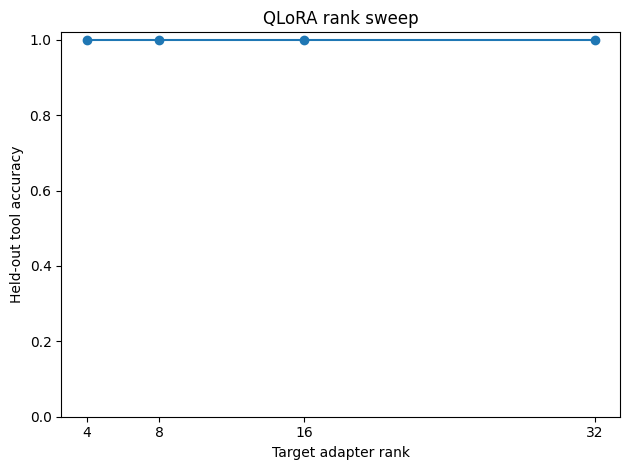

In [4]:
import matplotlib.pyplot as plt
comparison=[run(method,0 if method=='Base' else 8) for method in ('Base','LoRA','QLoRA','DoRA','AdaLoRA')]
# Validation alone selects the method. Do not inspect held-out files before freezing this rule.
winner=max(comparison[1:],key=lambda row:(row['val_tool'],row['val_full'],-row['peak_gib']))
sweep=[run(winner['method'],r) for r in (4,16,32)]+[winner]
sweep.sort(key=lambda row:row['rank'])
for name,rows in [('comparison',comparison),('rank_sweep',sweep)]:
    with (out/f'{name}.csv').open('w',newline='') as f:
        writer=csv.DictWriter(f,fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
plt.plot([r['rank'] for r in sweep],[r['tool']/r['n'] for r in sweep],marker='o')
plt.xticks([4,8,16,32])
plt.ylim(0,1.02)
plt.xlabel('Target adapter rank')
plt.ylabel('Held-out tool accuracy')
plt.title(winner['method']+' rank sweep')
plt.tight_layout()
plt.savefig(out/'rank_accuracy.png',dpi=180)
tag=f"{winner['method']}_r8"
predictions=[json.loads(line) for line in (out/f'{tag}_test.jsonl').read_text().splitlines()]
failures=[p for p in predictions if not p['full']][:5]
(out/'failure_examples.json').write_text(json.dumps(failures,indent=2))
print(comparison,winner,sweep,failures)
